In [1]:
# Standard Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import SGD, Adam

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler , OneHotEncoder
from sklearn.metrics import accuracy_score , confusion_matrix , classification_report

In [2]:
df = pd.read_csv('./datasets/iris.csv')
print(df.shape)
print(df.head())
print("\n\nInfo : ")
print(df.info())

(150, 5)
   sepal_length  sepal_width  petal_length  petal_width      species
0           5.1          3.5           1.4          0.2  Iris-setosa
1           4.9          3.0           1.4          0.2  Iris-setosa
2           4.7          3.2           1.3          0.2  Iris-setosa
3           4.6          3.1           1.5          0.2  Iris-setosa
4           5.0          3.6           1.4          0.2  Iris-setosa


Info : 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB
None


In [3]:
df['species'].value_counts()

species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

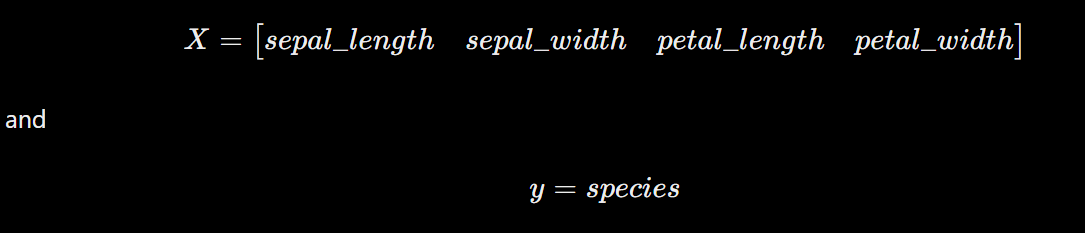

In [4]:
# separate the species and target
X = df.drop("species" , axis=1)
y = df["species"]
print(X.shape)
print(y.shape)
print(type(X))
print(type(y))

(150, 4)
(150,)
<class 'pandas.core.frame.DataFrame'>
<class 'pandas.core.series.Series'>


Both Label Encoding and One-Hot Encoding are techniques used to convert categorical data into numerical formats that machine learning models can read, as outlined


Label Encoding

Label Encoding assigns a unique integer to each category in a single column.
• How it works: For example, a Severity column with ['Low', 'Medium', 'High'] becomes [0, 1, 2].
• Best used for: Ordinal data—categories that possess a natural, meaningful order (e.g., Low < Medium < High, or educational degrees).


One-Hot Encoding

One-Hot Encoding converts each category into its own separate binary column (0 or 1).
• How it works: For a Color column with ['Red', 'Blue', 'Green'], it creates three columns (Is_Red, Is_Blue, Is_Green) and assigns 1 to the matching column and 0 to the rest.
• Best used for: Nominal data—categories with no natural order (e.g., countries, animal types, colors).

OneHotEncode the target column

In [6]:
# split the dataset into train and test set
X_train , X_test , y_train , y_test = train_test_split(X , y , test_size=0.1 , stratify=y , random_state=42)
print(f"X Train : {X_train.shape}")
print(f"X Test : {X_test.shape}")
print(f"y Train : {y_train.shape}")
print(f"y Test : {y_test.shape}")

print("Training Set : \n")
y_train.value_counts()

X Train : (135, 4)
X Test : (15, 4)
y Train : (135,)
y Test : (15,)
Training Set : 



species
Iris-setosa        45
Iris-virginica     45
Iris-versicolor    45
Name: count, dtype: int64

In [7]:
encoder = OneHotEncoder(sparse_output=False)

y_train = encoder.fit_transform(y_train.to_numpy().reshape(-1, 1))
y_test = encoder.transform(y_test.to_numpy().reshape(-1, 1))
print(type(y_train))
print(y_train.shape)

<class 'numpy.ndarray'>
(135, 3)


In [8]:
X_train = X_train.to_numpy()
X_test = X_test.to_numpy()

print(X_train.shape)
print(X_test.shape)
print(type(X_train))

(135, 4)
(15, 4)
<class 'numpy.ndarray'>


In [9]:
# standardize X
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [10]:
def train(optimizer , epochs , batch_size):
    model = Sequential([
        Dense(16 , activation="relu"),
        Dense(3 , activation="softmax")
    ])
    
    model.compile(
        loss="categorical_crossentropy",
        optimizer=optimizer,
        metrics=["accuracy"]
    )

    history = model.fit(
        X_train, y_train,
        epochs = epochs,
        batch_size=batch_size
    )

    return model , history

In [11]:
print(f"Training model with Batch Gradient Descent : \n")
bgd = model_batch_gd = train(SGD(learning_rate=0.01) , 50 , 135)
print(f"\nTraining model with Stochastic Gradient Descent : \n")
sgd = model_sgd = train(SGD(learning_rate=0.01) , 50 , 1)
print(f"\nTraining model with Adam Optimizer : \n")
adam = model_adam = train(Adam(learning_rate=0.001) , 50 , 1)

Training model with Batch Gradient Descent : 

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 694ms/step - accuracy: 0.3185 - loss: 1.0745
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.3185 - loss: 1.0652
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.3259 - loss: 1.0561
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.3259 - loss: 1.0474
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.3333 - loss: 1.0388
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.3333 - loss: 1.0304
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.3333 - loss: 1.0223
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.3407 - loss: 1.0144
Epoch 9/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.3407 - loss: 1.0066
Epoch 10/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.3407 - loss: 0.9992
Epoch 11/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.3407 - loss: 0.9919
Epoch 12/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 

In [12]:
adam[0].summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                      │ (1, 16)                     │              80 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (1, 3)                      │              51 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 395 (1.55 KB)

 Trainable params: 131 (524.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 264 (1.04 KB)

In [13]:
bgd_history = bgd[1]
sgd_history = sgd[1]
adam_history = adam[1]
print(bgd_history.history["loss"])
print()
print(sgd_history.history["loss"])
print()
print(adam_history.history["loss"])

[1.0745176076889038, 1.0652008056640625, 1.0561496019363403, 1.047370433807373, 1.0387816429138184, 1.0304105281829834, 1.0222723484039307, 1.0143520832061768, 1.0066438913345337, 0.9991548657417297, 0.9918861389160156, 0.9848147034645081, 0.9779201745986938, 0.9711766242980957, 0.9646106958389282, 0.9582158923149109, 0.9519838690757751, 0.945909321308136, 0.9399688243865967, 0.9341643452644348, 0.92849200963974, 0.9229558706283569, 0.9175474643707275, 0.912250280380249, 0.9070737957954407, 0.9020137190818787, 0.8970721364021301, 0.8922516107559204, 0.8875386714935303, 0.8829476833343506, 0.8784762620925903, 0.8740991353988647, 0.8698087334632874, 0.8656023144721985, 0.8614779710769653, 0.8574352860450745, 0.8534735441207886, 0.8495957255363464, 0.8457956910133362, 0.842055082321167, 0.8383530378341675, 0.8347161412239075, 0.8311376571655273, 0.8276342153549194, 0.8241872191429138, 0.8207805156707764, 0.8174370527267456, 0.8141571879386902, 0.8109310269355774, 0.8077569007873535]

[0.8

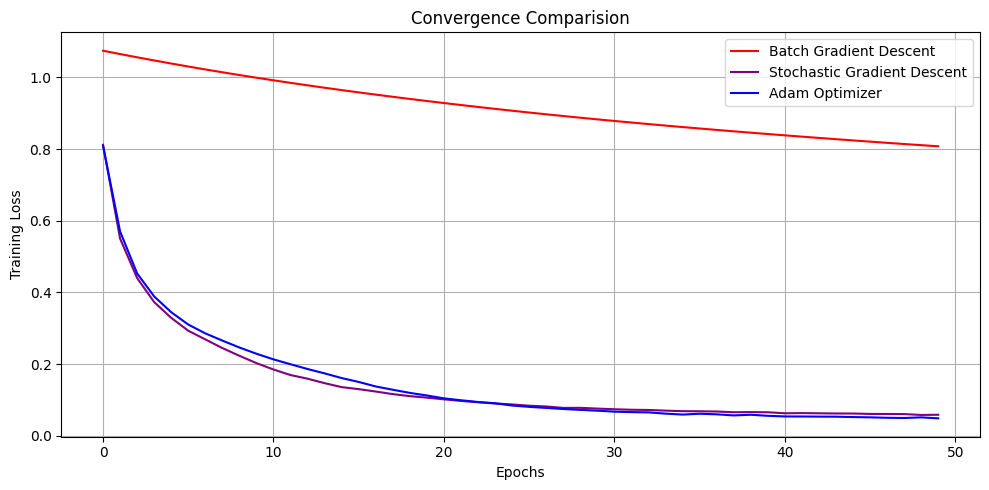

In [14]:
plt.figure(figsize=(10,5))
plt.plot(bgd_history.history["loss"] , label="Batch Gradient Descent" , color="red")
plt.plot(sgd_history.history["loss"] , label="Stochastic Gradient Descent" , color="purple")
plt.plot(adam_history.history["loss"] , label="Adam Optimizer" , color="blue")

plt.title("Convergence Comparision")
plt.xlabel("Epochs")
plt.ylabel("Training Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [15]:
bgd_model = bgd[0]
sgd_model = sgd[0]
adam_model = adam[0]

print("Batch GD:")
print(bgd_model.evaluate(X_test, y_test))

print("\nSGD:")
print(sgd_model.evaluate(X_test, y_test))

print("\nAdam:")
print(adam_model.evaluate(X_test, y_test))

Batch GD:
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 268ms/step - accuracy: 0.7333 - loss: 0.7977
[0.7976838946342468, 0.7333333492279053]

SGD:
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 621ms/step - accuracy: 0.8667 - loss: 0.1214
[0.12138546258211136, 0.8666666746139526]

Adam:
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 227ms/step - accuracy: 0.8667 - loss: 0.1466
[0.146586075425148, 0.8666666746139526]


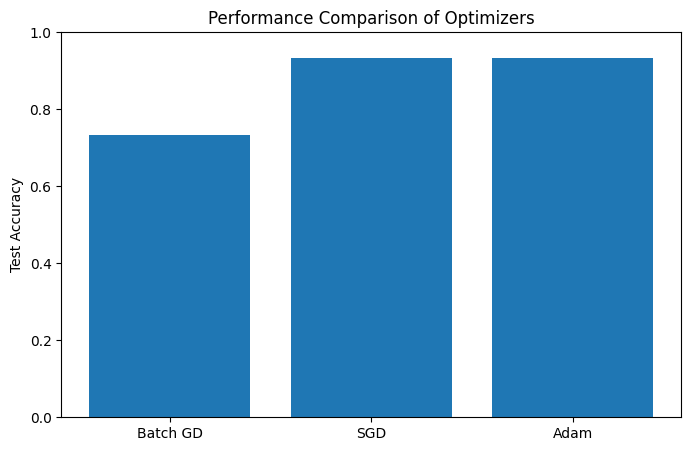

In [16]:
optimizers = ["Batch GD", "SGD", "Adam"]
accuracy = [0.7333333492279053, 0.9333333373069763, 0.9333333373069763]

plt.figure(figsize=(8, 5))
plt.bar(optimizers, accuracy)

plt.ylabel("Test Accuracy")
plt.title("Performance Comparison of Optimizers")
plt.ylim(0, 1)

plt.show()